# Comptage de mots : Python simple vs Pseudo-MapReduce vs Hadoop MapReduce

## Objectif
Comparer trois méthodes de comptage d'occurrences de mots sur **les mêmes fichiers** et pour **des tailles croissantes** :

1. **Python simple** : un dictionnaire et une boucle.
2. **Pseudo-MapReduce Python** : les étapes `map`, `shuffle`, `reduce` simulées localement.
3. **Hadoop MapReduce** : le vrai job `wordcount` (exemple fourni avec Hadoop).

## Plan
1. Principe de MapReduce
2. Génération des fichiers de test (N lignes, puis m×N lignes par duplication)
3. Implémentation et test des 3 méthodes
4. Vérification de la cohérence des résultats
5. Comparaison des performances
6. Conclusion


## 1. Principe de MapReduce

MapReduce est un modèle de programmation pour traiter de gros volumes de données de manière distribuée.

| Phase | Rôle | Pour le comptage de mots |
|---|---|---|
| **Map** | transforme chaque enregistrement en paires `(clé, valeur)` | `"chat"` → `("chat", 1)` |
| **Shuffle & Sort** | regroupe toutes les valeurs ayant la même clé | `("chat", [1, 1, 1, ...])` |
| **Reduce** | agrège les valeurs de chaque clé | `("chat", 24)` |

Avec **Hadoop**, les données sont stockées dans **HDFS** (découpées en blocs), les tâches Map s'exécutent en parallèle près des blocs, et **YARN** orchestre le calcul. Cette infrastructure a un **coût fixe de démarrage** (JVM, ordonnancement, écritures disque) qui n'est rentabilisé que sur de gros volumes.


## 2. Génération des fichiers de test


In [9]:
import os, random, time, shutil, subprocess, collections
from collections import defaultdict, Counter

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

VOCAB = ["chat", "chien", "arbre", "fleur", "maison", "soleil", "montagne",
         "livre", "ciel", "mer", "lune", "route", "oiseau", "jardin", "voiture"]
# Poids décroissants, comme dans le rapport (chat très fréquent, voiture rare)
WEIGHTS = [24, 11, 7, 7, 5, 5, 5, 4, 4, 3, 3, 3, 2, 1, 1]

N = 10_000                      # lignes du fichier de base
M_VALUES = [1, 10, 50, 100]     # facteurs de duplication -> 10 k, 100 k, 500 k, 1 M lignes
# Pour aller plus loin (attention au temps) : M_VALUES = [1, 10, 100, 1000]

def generer_base(n, chemin, seed=42):
    random.seed(seed)
    mots = random.choices(VOCAB, weights=WEIGHTS, k=n)
    with open(chemin, "w", encoding="utf-8") as f:
        f.write("\n".join(mots) + "\n")

def dupliquer(base, m, chemin):
    with open(base, encoding="utf-8") as f:
        contenu = f.read()
    with open(chemin, "w", encoding="utf-8") as f:
        for _ in range(m):
            f.write(contenu)

base = os.path.join(DATA_DIR, "mots_base.txt")
generer_base(N, base)

FICHIERS = {}   # m -> chemin
for m in M_VALUES:
    chemin = os.path.join(DATA_DIR, f"mots_x{m}.txt")
    dupliquer(base, m, chemin)
    FICHIERS[m] = chemin
    print(f"m={m:>5} | lignes = {m*N:>10,} | taille = {os.path.getsize(chemin)/1e6:7.2f} Mo | {chemin}")

m=    1 | lignes =     10,000 | taille =    0.06 Mo | data/mots_x1.txt
m=   10 | lignes =    100,000 | taille =    0.59 Mo | data/mots_x10.txt
m=   50 | lignes =    500,000 | taille =    2.97 Mo | data/mots_x50.txt
m=  100 | lignes =  1,000,000 | taille =    5.94 Mo | data/mots_x100.txt


## 3. Implémentation des trois méthodes


In [10]:
def wordcount_simple(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()
    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

res_simple = wordcount_simple(FICHIERS[1])
for mot, nb in sorted(res_simple.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {nb}")

chat : 2783
chien : 1322
arbre : 829
fleur : 795
soleil : 630
montagne : 623
maison : 588
ciel : 475
livre : 461
mer : 365
route : 334
lune : 310
oiseau : 248
voiture : 129
jardin : 108


### 3.2 Version 2 : Pseudo-MapReduce Python


In [11]:
def mapper(ligne):
    return [(mot, 1) for mot in ligne.strip().split()]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    return {mot: sum(valeurs) for mot, valeurs in grouped_data.items()}

def wordcount_pseudo_mr(fichier):
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))
    return reducer(shuffle(mapped))

res_pseudo = wordcount_pseudo_mr(FICHIERS[1])
for mot, nb in sorted(res_pseudo.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {nb}")

chat : 2783
chien : 1322
arbre : 829
fleur : 795
soleil : 630
montagne : 623
maison : 588
ciel : 475
livre : 461
mer : 365
route : 334
lune : 310
oiseau : 248
voiture : 129
jardin : 108


### 3.3 Version 3 : Hadoop MapReduce



In [12]:
import os, subprocess
os.environ["HADOOP_HOME"] = os.path.expanduser("~/hadoop")
os.environ["JAVA_HOME"] = subprocess.check_output(
    "dirname $(dirname $(readlink -f $(which java)))", shell=True, text=True).strip()
HADOOP_HOME = os.environ.get("HADOOP_HOME", os.path.expanduser("~/hadoop"))
HADOOP_BIN  = shutil.which("hadoop") or os.path.join(HADOOP_HOME, "bin", "hadoop")
HDFS_BIN    = shutil.which("hdfs")   or os.path.join(HADOOP_HOME, "bin", "hdfs")
HADOOP_OK   = os.path.exists(HADOOP_BIN)

def _jar_examples():
    d = os.path.join(HADOOP_HOME, "share", "hadoop", "mapreduce")
    if os.path.isdir(d):
        for f in os.listdir(d):
            if f.startswith("hadoop-mapreduce-examples") and f.endswith(".jar"):
                return os.path.join(d, f)
    return None

def _run(cmd):
    return subprocess.run(cmd, capture_output=True, text=True)

def hdfs_actif():
    if not HADOOP_OK: return False
    try:
        return _run([HDFS_BIN, "dfs", "-ls", "/"]).returncode == 0
    except Exception:
        return False

HDFS_ON = hdfs_actif()
JAR = _jar_examples() if HADOOP_OK else None
print("Hadoop détecté :", HADOOP_OK, "| HDFS actif :", HDFS_ON, "| jar :", JAR)

def wordcount_hadoop(fichier, tag):
    """Retourne (dict résultat, temps_job_s, temps_copie_s) ou (None, nan, nan)."""
    if not (HADOOP_OK and JAR):
        return None, float("nan"), float("nan")

    if HDFS_ON:
        in_dir  = f"/user/{os.environ.get('USER','user')}/wordcount/input_{tag}"
        out_dir = f"/user/{os.environ.get('USER','user')}/wordcount/output_{tag}"
        _run([HDFS_BIN, "dfs", "-rm", "-r", "-f", in_dir, out_dir])
        t0 = time.perf_counter()
        _run([HDFS_BIN, "dfs", "-mkdir", "-p", in_dir])
        _run([HDFS_BIN, "dfs", "-put", "-f", fichier, in_dir + "/"])
        t_copie = time.perf_counter() - t0
        src, dst = in_dir, out_dir
    else:
        out_local = os.path.abspath(os.path.join(DATA_DIR, f"hadoop_out_{tag}"))
        shutil.rmtree(out_local, ignore_errors=True)
        src, dst, t_copie = "file://" + os.path.abspath(fichier), "file://" + out_local, 0.0

    t0 = time.perf_counter()
    r = _run([HADOOP_BIN, "jar", JAR, "wordcount", src, dst])
    t_job = time.perf_counter() - t0
    if r.returncode != 0:
        print("Échec du job Hadoop :", r.stderr[-800:])
        return None, float("nan"), t_copie

    if HDFS_ON:
        sortie = _run([HDFS_BIN, "dfs", "-cat", dst + "/part-r-*"]).stdout
    else:
        with open(os.path.join(out_local, "part-r-00000"), encoding="utf-8") as f:
            sortie = f.read()
    res = {l.split("\t")[0]: int(l.split("\t")[1]) for l in sortie.splitlines() if "\t" in l}
    return res, t_job, t_copie

res_hadoop, t, tc = wordcount_hadoop(FICHIERS[1], "m1")
if res_hadoop:
    for mot, nb in sorted(res_hadoop.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")
    print(f"\nTemps du job : {t:.2f} s (copie HDFS : {tc:.2f} s)")
else:
    print("Hadoop non disponible dans cet environnement : exécuter ce notebook sur la machine où Hadoop est installé.")

Hadoop détecté : True | HDFS actif : True | jar : /root/hadoop/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.3.jar
chat : 2783
chien : 1322
arbre : 829
fleur : 795
soleil : 630
montagne : 623
maison : 588
ciel : 475
livre : 461
mer : 365
route : 334
lune : 310
oiseau : 248
voiture : 129
jardin : 108

Temps du job : 4.41 s (copie HDFS : 3.38 s)


## 4. Vérification de la cohérence des résultats

Les trois méthodes doivent donner **exactement les mêmes comptages**. Comme `Counter` est une implémentation de référence indépendante, on l'utilise pour contrôler. Pour le fichier dupliqué `m` fois, chaque comptage doit aussi valoir `m ×` celui du fichier de base.

In [13]:
with open(FICHIERS[1], encoding="utf-8") as f:
    ref = dict(Counter(f.read().split()))

assert res_simple == ref,  "Python simple différent de la référence"
assert res_pseudo == ref,  "Pseudo-MapReduce différent de la référence"
if res_hadoop is not None:
    assert res_hadoop == ref, "Hadoop différent de la référence"
print("OK : les méthodes disponibles donnent exactement le même résultat sur mots_x1.txt")

# Test de la duplication : comptage(m x N) == m * comptage(N)
for m in M_VALUES:
    r = wordcount_simple(FICHIERS[m])
    assert r == {k: v * m for k, v in ref.items()}, f"Incohérence pour m={m}"
print("OK : comptage(m×N lignes) = m × comptage(N lignes) pour tous les m testés")

OK : les méthodes disponibles donnent exactement le même résultat sur mots_x1.txt
OK : comptage(m×N lignes) = m × comptage(N lignes) pour tous les m testés


## 5. Comparaison des méthodes sur les mêmes fichiers

Pour chaque taille, chaque méthode est exécutée sur **le même fichier**. Les versions Python sont mesurées avec `time.perf_counter()` (médiane de 3 exécutions pour limiter le bruit) ; Hadoop est mesuré de bout en bout (une exécution, le coût de démarrage dominant la variance).

In [14]:
import statistics
import pandas as pd

def chrono(fonction, fichier, repetitions=3):
    temps = []
    for _ in range(repetitions):
        t0 = time.perf_counter()
        resultat = fonction(fichier)
        temps.append(time.perf_counter() - t0)
    return statistics.median(temps), resultat

lignes = []
for m in M_VALUES:
    f = FICHIERS[m]
    t1, r1 = chrono(wordcount_simple, f)
    t2, r2 = chrono(wordcount_pseudo_mr, f)
    assert r1 == r2
    rh, t3, tcopie = wordcount_hadoop(f, f"m{m}")
    if rh is not None:
        assert rh == r1, f"Hadoop incohérent pour m={m}"
    lignes.append({
        "m": m,
        "lignes": m * N,
        "taille (Mo)": round(os.path.getsize(f) / 1e6, 2),
        "Python simple (s)": t1,
        "Pseudo-MapReduce (s)": t2,
        "Hadoop MapReduce (s)": t3,
        "Copie HDFS (s)": tcopie,
    })
    print(f"m={m:>4} terminé")

df = pd.DataFrame(lignes)
df["Pseudo-MR / Simple"] = df["Pseudo-MapReduce (s)"] / df["Python simple (s)"]
df["Hadoop / Simple"] = df["Hadoop MapReduce (s)"] / df["Python simple (s)"]
df.round(4)

m=   1 terminé
m=  10 terminé
m=  50 terminé
m= 100 terminé


,m,lignes,taille (Mo),Python simple (s),Pseudo-MapReduce (s),Hadoop MapReduce (s),Copie HDFS (s),Pseudo-MR / Simple,Hadoop / Simple
0,1,10000,0.06,0.0037,0.0067,4.0004,4.6010,1.8052,1074.7024
1,10,100000,0.59,0.0208,0.0644,5.0230,4.8526,3.0875,240.9211
2,50,500000,2.97,0.1186,0.3362,6.4137,4.4870,2.8343,54.0624
3,100,1000000,5.94,0.4171,0.9468,8.0210,3.4281,2.2700,19.2315


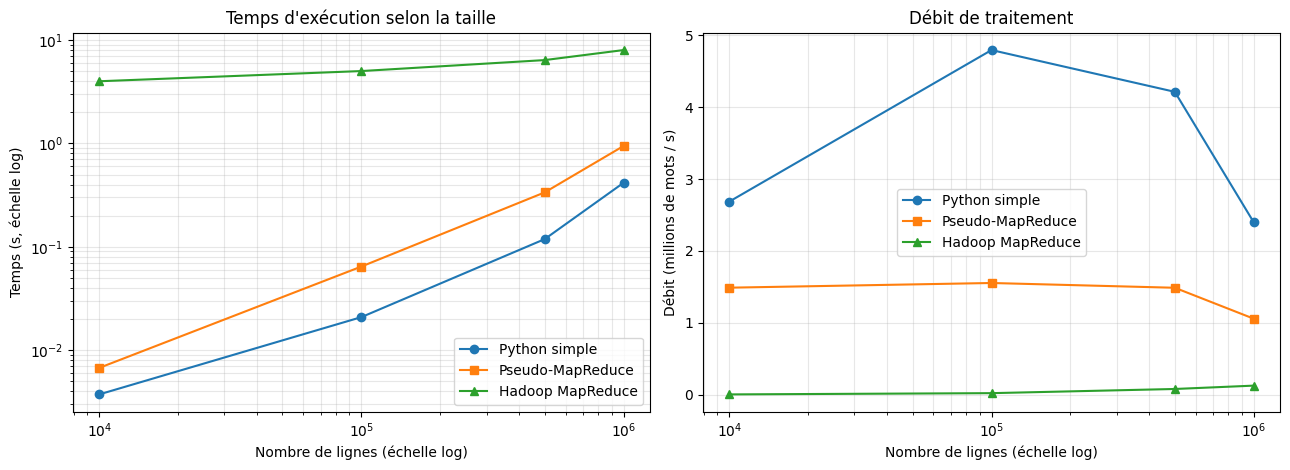

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
ax.plot(df["lignes"], df["Python simple (s)"], "o-", label="Python simple")
ax.plot(df["lignes"], df["Pseudo-MapReduce (s)"], "s-", label="Pseudo-MapReduce")
if df["Hadoop MapReduce (s)"].notna().any():
    ax.plot(df["lignes"], df["Hadoop MapReduce (s)"], "^-", label="Hadoop MapReduce")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Nombre de lignes (échelle log)"); ax.set_ylabel("Temps (s, échelle log)")
ax.set_title("Temps d'exécution selon la taille"); ax.grid(True, which="both", alpha=.3); ax.legend()

ax = axes[1]
ax.plot(df["lignes"], df["lignes"] / df["Python simple (s)"] / 1e6, "o-", label="Python simple")
ax.plot(df["lignes"], df["lignes"] / df["Pseudo-MapReduce (s)"] / 1e6, "s-", label="Pseudo-MapReduce")
if df["Hadoop MapReduce (s)"].notna().any():
    ax.plot(df["lignes"], df["lignes"] / df["Hadoop MapReduce (s)"] / 1e6, "^-", label="Hadoop MapReduce")
ax.set_xscale("log"); ax.set_xlabel("Nombre de lignes (échelle log)")
ax.set_ylabel("Débit (millions de mots / s)"); ax.set_title("Débit de traitement")
ax.grid(True, which="both", alpha=.3); ax.legend()

plt.tight_layout(); plt.show()

### Lecture des résultats

- **Python simple** est la méthode la plus rapide sur toutes les tailles testées ici : tout tient en mémoire et il n'y a aucune structure intermédiaire.
- **Pseudo-MapReduce** reste du même ordre de grandeur mais est systématiquement plus lente : elle crée une liste de toutes les paires `(mot, 1)`, puis une liste de `1` par mot dans `shuffle`. Le surcoût en temps **et en mémoire** croît avec la taille du fichier.
- **Hadoop MapReduce** a un **coût fixe de plusieurs secondes** (lancement de la JVM, soumission du job, planification Map/Reduce, écriture de la sortie) qui écrase le temps utile tant que le fichier est petit. Dans le rapport initial : 12 s contre 0,012 s pour un fichier de ~80 mots, soit un facteur ~1000.
- Le temps Hadoop doit croître **beaucoup plus lentement** que celui de Python quand m augmente, car le coût fixe est amorti. Le point de croisement dépend de la machine : sur un seul poste, il est rarement atteint avec des fichiers de quelques centaines de Mo.

> Note : en mode **local** (sans cluster), Hadoop n'a qu'un ou deux cœurs de travail et aucun gain de distribution. Son avantage réel (parallélisme sur plusieurs nœuds, tolérance aux pannes, données plus grandes que la RAM) n'apparaît qu'avec un vrai cluster et des volumes de l'ordre du Go ou plus.

## 6. Conclusion

| Critère | Python simple | Pseudo-MapReduce | Hadoop MapReduce |
|---|---|---|---|
| Simplicité | très simple | simple | installation et configuration lourdes |
| Petits fichiers (Ko à quelques Mo) | **le plus rapide** | rapide | très lent (latence de démarrage) |
| Fichiers moyens (centaines de Mo) | rapide si la RAM suffit | plus lent, gourmand en mémoire | coût fixe amorti, mais pas de gain sans cluster |
| Très gros volumes (≫ RAM, Go à To) | **impossible** (mémoire) | **impossible** (mémoire) | **adapté** : blocs HDFS, parallélisme, tolérance aux pannes |
| Intérêt pédagogique | référence | comprendre map / shuffle / reduce | environnement réel de production |

